# ⚽ Análise de Dados do Campeonato Brasileiro (2003–2024)

Neste notebook exploro **mais de 8.700 partidas** do Brasileirão Série A para responder perguntas como:

1. O **fator casa** realmente existe? Mudou ao longo dos anos?
2. Quantos **gols por jogo** saem no campeonato?
3. Quem são os **maiores campeões** da era dos pontos corridos?
4. Quantos **pontos** é preciso fazer para ser campeão, ir para o G4 ou fugir do rebaixamento?
5. Quais times têm o **melhor desempenho em casa e fora**?
6. É possível **prever o resultado** de um jogo usando só o histórico dos times?

**Fonte dos dados:** [adaoduque/Brasileirao_Dataset](https://github.com/adaoduque/Brasileirao_Dataset) (dados públicos de partidas).

**Roteiro:** Setup → Limpeza → Análise exploratória → Campeões → Desempenho dos times → Modelo preditivo → Conclusões

## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# permite importar o módulo src/ quando o notebook roda dentro de notebooks/
sys.path.append(str(Path.cwd().parent))
from src.data_processing import carregar_dados, formato_longo, tabela_classificacao

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

IMG = Path.cwd().parent / "images"
IMG.mkdir(exist_ok=True)

def salvar(fig, nome):
    fig.savefig(IMG / f"{nome}.png", bbox_inches="tight", dpi=130)

## 2. Carregando e limpando os dados

As etapas de limpeza ficam em `src/data_processing.py` para poderem ser reutilizadas. Elas:
- convertem a coluna de data para o formato `datetime`;
- criam a coluna `temporada` (a de **2020 terminou em fevereiro de 2021** por causa da pandemia, então não dá para usar apenas o ano da data);
- calculam `gols_total` e o `resultado` de cada jogo (Mandante / Empate / Visitante).

In [2]:
df = carregar_dados()
print(f"{len(df):,} partidas | {df['temporada'].min()} a {df['temporada'].max()} | {df['mandante'].nunique()} clubes")
df.head()

8,785 partidas | 2003 a 2024 | 45 clubes


,ID,rodata,data,hora,mandante,visitante,formacao_mandante,formacao_visitante,tecnico_mandante,tecnico_visitante,vencedor,arena,gols_mandante,gols_visitante,mandante_Estado,visitante_Estado,temporada,gols_total,resultado
0,1,1,2003-03-29,16:00,Guarani,Vasco,NaN,NaN,NaN,NaN,Guarani,Brinco de Ouro,4,2,SP,RJ,2003,6,Mandante
1,2,1,2003-03-29,16:00,Athletico-PR,Gremio,NaN,NaN,NaN,NaN,Athletico-PR,Arena da Baixada,2,0,PR,RS,2003,2,Mandante
2,3,1,2003-03-30,16:00,Flamengo,Coritiba,NaN,NaN,NaN,NaN,-,Maracanã,1,1,RJ,PR,2003,2,Empate
3,4,1,2003-03-30,16:00,Goias,Paysandu,NaN,NaN,NaN,NaN,-,Serra Dourada,2,2,GO,PA,2003,4,Empate
4,5,1,2003-03-30,16:00,Internacional,Ponte Preta,NaN,NaN,NaN,NaN,-,Beira Rio,1,1,RS,SP,2003,2,Empate


In [3]:
# Valores ausentes: formações e técnicos só existem para parte dos jogos
df.isna().mean().round(3).to_frame("% ausente").query("`% ausente` > 0")

,% ausente
formacao_mandante,0.566
formacao_visitante,0.566
tecnico_mandante,0.525
tecnico_visitante,0.525


In [4]:
# Partidas por temporada: 2003-2005 tiveram formatos diferentes (mais times e rodadas)
jogos = df.groupby("temporada").size()
jogos.to_frame("jogos").T

temporada,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
jogos,552,552,462,380,380,380,380,380,380,380,...,380,379,380,380,380,380,380,380,380,380


> **Observação:** de 2003 a 2005 o campeonato teve formatos diferentes (24 e 22 clubes). Por isso, as análises de **classificação e campeões** usam apenas **2006–2024**, quando o formato de 20 clubes em pontos corridos se consolidou. A análise exploratória geral e o modelo usam toda a base.

## 3. Análise exploratória

### 3.1 O fator casa

resultado
Mandante     49.6
Empate       26.4
Visitante    24.0


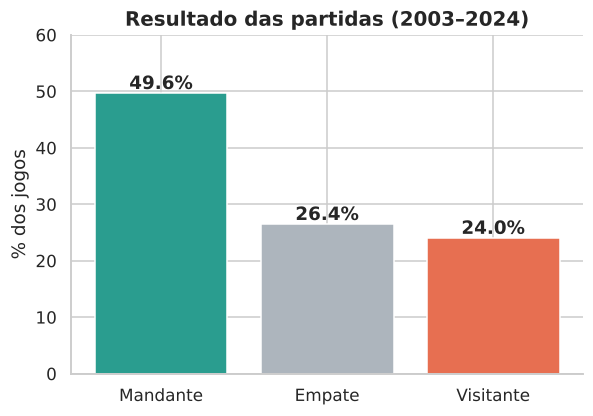

In [5]:
res = df["resultado"].value_counts(normalize=True).reindex(["Mandante", "Empate", "Visitante"]) * 100
print(res.round(1).to_string())

fig, ax = plt.subplots(figsize=(6, 4))
cores = ["#2a9d8f", "#adb5bd", "#e76f51"]
ax.bar(res.index, res.values, color=cores)
for i, v in enumerate(res.values):
    ax.text(i, v + 0.8, f"{v:.1f}%", ha="center", fontweight="bold")
ax.set(title="Resultado das partidas (2003–2024)", ylabel="% dos jogos", ylim=(0, 60))
sns.despine()
salvar(fig, "01_resultados_gerais")
plt.show()

O mandante vence cerca de **metade** dos jogos, enquanto o visitante vence menos de um quarto. Será que isso mudou com o tempo?

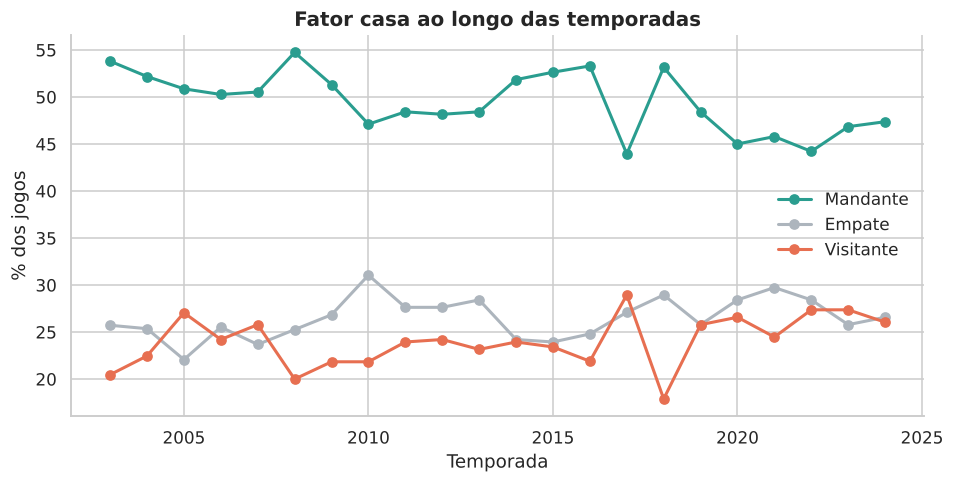

In [6]:
por_temp = (
    df.groupby("temporada")["resultado"].value_counts(normalize=True).unstack()[["Mandante", "Empate", "Visitante"]] * 100
)

fig, ax = plt.subplots(figsize=(10, 4.5))
for col, cor in zip(por_temp.columns, cores):
    ax.plot(por_temp.index, por_temp[col], marker="o", label=col, color=cor, lw=2)
ax.set(title="Fator casa ao longo das temporadas", xlabel="Temporada", ylabel="% dos jogos")
ax.legend(frameon=False)
sns.despine()
salvar(fig, "02_fator_casa_temporadas")
plt.show()

In [7]:
antes = por_temp.loc[2003:2016, "Mandante"].mean()
depois = por_temp.loc[2017:2024, "Mandante"].mean()
print(f"Vitórias do mandante 2003–2016: {antes:.1f}%")
print(f"Vitórias do mandante 2017–2024: {depois:.1f}%")
print(f"Diferença: {depois - antes:.1f} p.p.")
print(f"Temporada com menor taxa: {por_temp['Mandante'].idxmin()} ({por_temp['Mandante'].min():.1f}%)")

Vitórias do mandante 2003–2016: 51.0%
Vitórias do mandante 2017–2024: 46.8%
Diferença: -4.1 p.p.
Temporada com menor taxa: 2017 (43.9%)


A vantagem de jogar em casa **diminuiu nos últimos anos**: de ~51% de vitórias do mandante (2003–2016) para ~47% (2017–2024). A queda não se concentra em 2020 (ano sem público): 2017 e 2022 tiveram taxas ainda menores. Possíveis explicações (que **este notebook não testa**) incluem o uso do VAR, mudanças no calendário e maior equilíbrio entre os times.

### 3.2 Gols por jogo

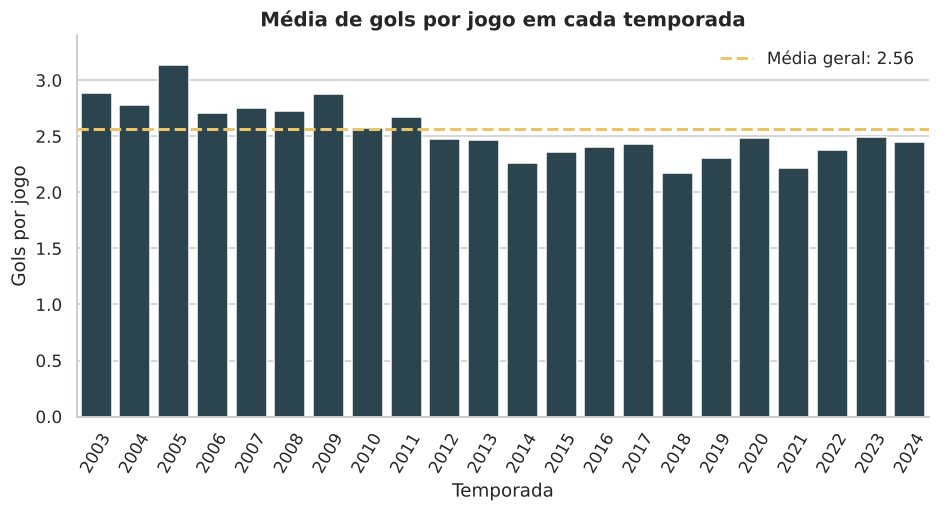

In [8]:
gols = df.groupby("temporada")["gols_total"].mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=gols.index, y=gols.values, color="#264653", ax=ax)
ax.axhline(df["gols_total"].mean(), color="#e9c46a", ls="--", lw=2, label=f"Média geral: {df['gols_total'].mean():.2f}")
ax.set(title="Média de gols por jogo em cada temporada", xlabel="Temporada", ylabel="Gols por jogo", ylim=(0, 3.4))
ax.tick_params(axis="x", rotation=60)
ax.legend(frameon=False)
sns.despine()
salvar(fig, "03_gols_por_jogo")
plt.show()

In [9]:
print("Temporada com mais gols/jogo:", gols.idxmax(), f"({gols.max():.2f})")
print("Temporada com menos gols/jogo:", gols.idxmin(), f"({gols.min():.2f})")

Temporada com mais gols/jogo: 2005 (3.13)
Temporada com menos gols/jogo: 2018 (2.18)


### 3.3 Placares mais comuns

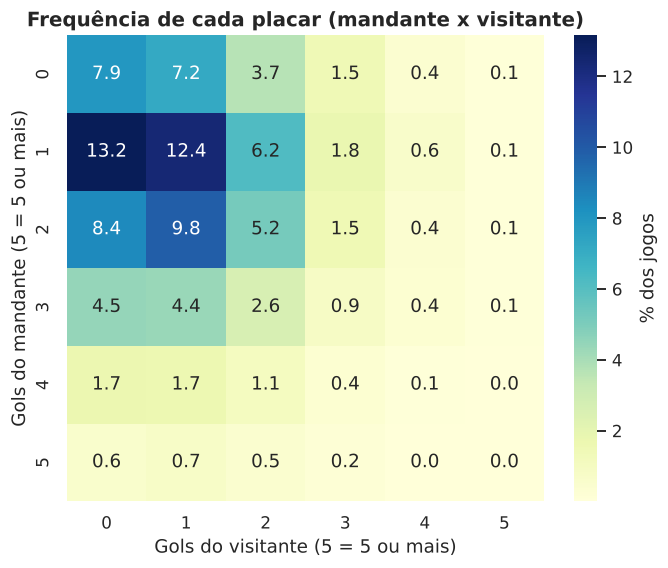

In [10]:
# limita a 5 gols para o gráfico ficar legível
placares = (
    df.assign(m=df["gols_mandante"].clip(upper=5), v=df["gols_visitante"].clip(upper=5))
    .groupby(["m", "v"]).size().unstack(fill_value=0)
)
pct = placares / placares.values.sum() * 100

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(pct, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "% dos jogos"}, ax=ax)
ax.set(title="Frequência de cada placar (mandante x visitante)", xlabel="Gols do visitante (5 = 5 ou mais)",
       ylabel="Gols do mandante (5 = 5 ou mais)")
salvar(fig, "04_heatmap_placares")
plt.show()

O placar mais comum é **1 x 0** para o mandante (cerca de 13% dos jogos), seguido de **1 x 1** (12%) e **2 x 1** (10%). Os jogos do Brasileirão são, em geral, de poucos gols.

## 4. Campeões e pontuação (2006–2024)

Para analisar classificações, converto os dados para o **formato longo** (uma linha por time em cada jogo) e calculo a tabela de cada temporada com vitória = 3 pontos, empate = 1.

In [11]:
longo = formato_longo(df)
temporadas = list(range(2006, 2025))

linhas = []
for t in temporadas:
    tab = tabela_classificacao(longo, t)
    linhas.append({
        "temporada": t,
        "campeao": tab.index[0],
        "pts_campeao": tab["Pts"].iloc[0],
        "pts_4o": tab["Pts"].iloc[3],
        "pts_17o": tab["Pts"].iloc[16],
    })
resumo = pd.DataFrame(linhas).set_index("temporada")
resumo

,campeao,pts_campeao,pts_4o,pts_17o
temporada,,,,
2006,Sao Paulo,78,64,39
2007,Sao Paulo,77,61,44
2008,Sao Paulo,75,65,44
2009,Flamengo,67,62,45
2010,Fluminense,71,63,42
2011,Corinthians,71,61,41
2012,Fluminense,77,66,41
2013,Cruzeiro,76,61,46
2014,Cruzeiro,80,69,38


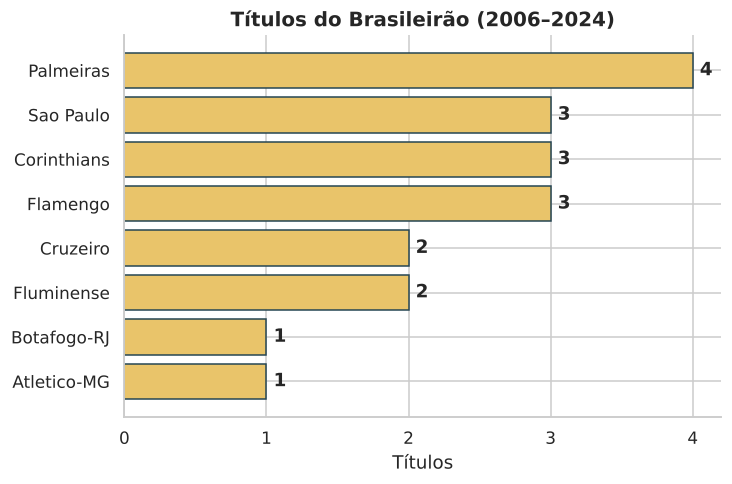

In [12]:
titulos = resumo["campeao"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(titulos.index, titulos.values, color="#e9c46a", edgecolor="#264653")
for y, v in enumerate(titulos.values):
    ax.text(v + 0.05, y, int(v), va="center", fontweight="bold")
ax.set(title="Títulos do Brasileirão (2006–2024)", xlabel="Títulos")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
sns.despine()
salvar(fig, "05_titulos")
plt.show()

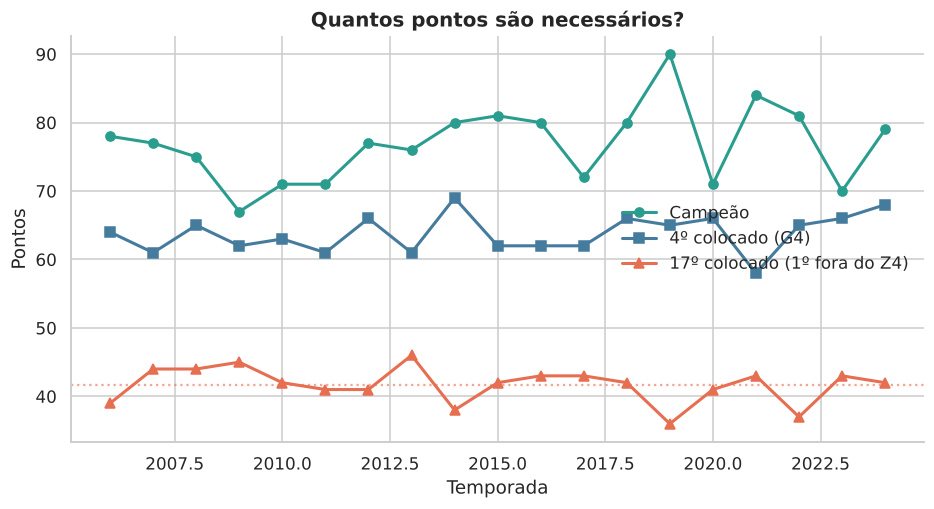

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(resumo.index, resumo["pts_campeao"], marker="o", lw=2, label="Campeão", color="#2a9d8f")
ax.plot(resumo.index, resumo["pts_4o"], marker="s", lw=2, label="4º colocado (G4)", color="#457b9d")
ax.plot(resumo.index, resumo["pts_17o"], marker="^", lw=2, label="17º colocado (1º fora do Z4)", color="#e76f51")
ax.axhline(resumo["pts_17o"].mean(), color="#e76f51", ls=":", alpha=.6)
ax.set(title="Quantos pontos são necessários?", xlabel="Temporada", ylabel="Pontos")
ax.legend(frameon=False, loc="center right")
sns.despine()
salvar(fig, "06_pontos_necessarios")
plt.show()

In [14]:
print(f"Média de pontos do campeão: {resumo['pts_campeao'].mean():.1f}")
print(f"Média de pontos do 4º colocado: {resumo['pts_4o'].mean():.1f}")
print(f"Média de pontos do 17º colocado (escapou do rebaixamento): {resumo['pts_17o'].mean():.1f}")
print(f"Maior pontuação de um campeão: {resumo['pts_campeao'].max()} ({resumo['pts_campeao'].idxmax()}, {resumo.loc[resumo['pts_campeao'].idxmax(), 'campeao']})")

Média de pontos do campeão: 76.8
Média de pontos do 4º colocado: 63.8
Média de pontos do 17º colocado (escapou do rebaixamento): 41.7
Maior pontuação de um campeão: 90 (2019, Flamengo)


Como regra de bolso, **~77 pontos** são a média de um campeão, **~64** costumam garantir o G4 e **~42** a permanência na Série A (a variação entre temporadas é grande, como mostra o gráfico).

## 5. Desempenho dos clubes (2006–2024)

### 5.1 Aproveitamento geral
Aproveitamento = pontos conquistados ÷ pontos disputados. Considero apenas clubes com pelo menos **5 temporadas** na série A no período, para evitar distorções.

In [15]:
l = longo[longo["temporada"].between(2006, 2024)]
geral = l.groupby("time").agg(
    jogos=("ID", "count"), pontos=("pontos", "sum"), gols_pro=("gols_pro", "sum"),
    gols_contra=("gols_contra", "sum"), temporadas=("temporada", "nunique"),
)
geral["aproveitamento"] = geral["pontos"] / (geral["jogos"] * 3) * 100
geral["saldo_gols"] = geral["gols_pro"] - geral["gols_contra"]
elegiveis = geral[geral["temporadas"] >= 5].sort_values("aproveitamento", ascending=False)
elegiveis.head(10).round(1)

,jogos,pontos,gols_pro,gols_contra,temporadas,aproveitamento,saldo_gols
time,,,,,,,
Flamengo,722,1178,1057,818,19,54.4,239
Sao Paulo,722,1165,980,745,19,53.8,235
Palmeiras,684,1101,984,761,18,53.7,223
Gremio,684,1089,949,736,18,53.1,213
Internacional,684,1069,898,724,18,52.1,174
Atletico-MG,683,1055,988,845,18,51.5,143
Corinthians,684,1051,851,701,18,51.2,150
Cruzeiro,608,913,812,691,16,50.1,121
Santos,684,1002,914,793,18,48.8,121


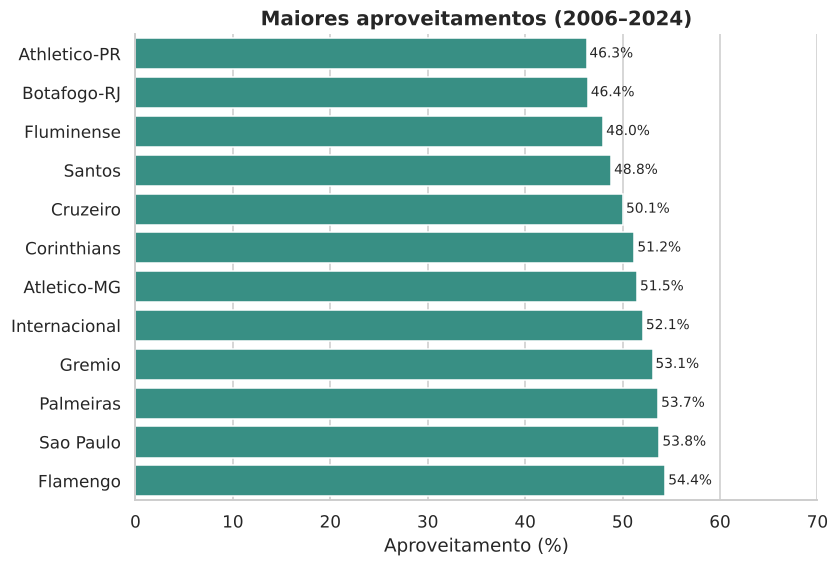

In [16]:
top = elegiveis.head(12).sort_values("aproveitamento")

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.barplot(x=top["aproveitamento"], y=top.index, color="#2a9d8f", ax=ax)
for y, v in enumerate(top["aproveitamento"]):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set(title="Maiores aproveitamentos (2006–2024)", xlabel="Aproveitamento (%)", ylabel="", xlim=(0, 70))
sns.despine()
salvar(fig, "07_aproveitamento_geral")
plt.show()

### 5.2 Casa vs. fora: quem mais depende do seu estádio?

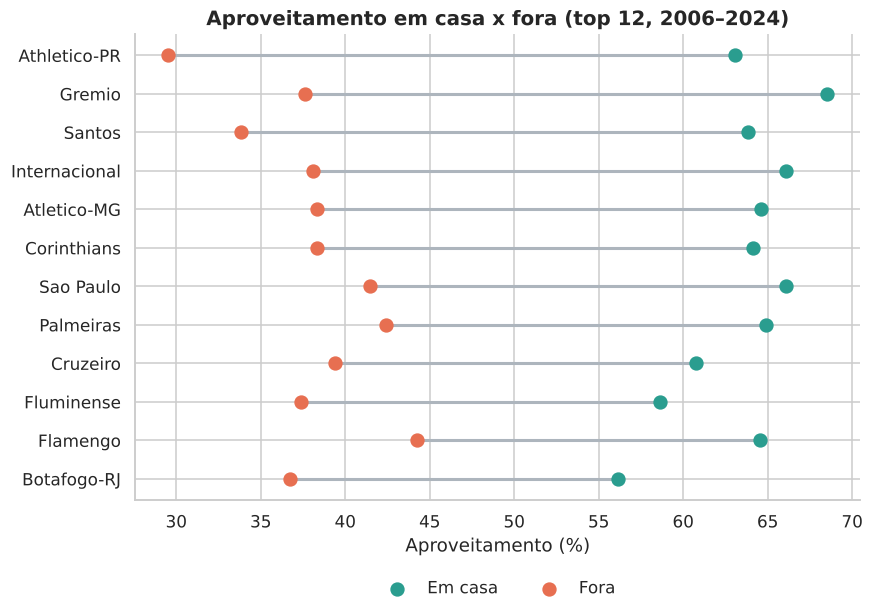

In [17]:
casa_fora = (
    l.groupby(["time", "local"]).agg(j=("ID", "count"), p=("pontos", "sum")).assign(aprov=lambda d: d.p / (d.j * 3) * 100)
    ["aprov"].unstack()
)
casa_fora = casa_fora.loc[elegiveis.index[:12]]
casa_fora["diferenca"] = casa_fora["Casa"] - casa_fora["Fora"]
casa_fora = casa_fora.sort_values("diferenca")

fig, ax = plt.subplots(figsize=(8.5, 5.5))
y = np.arange(len(casa_fora))
ax.hlines(y, casa_fora["Fora"], casa_fora["Casa"], color="#adb5bd", lw=2)
ax.scatter(casa_fora["Casa"], y, color="#2a9d8f", s=70, label="Em casa", zorder=3)
ax.scatter(casa_fora["Fora"], y, color="#e76f51", s=70, label="Fora", zorder=3)
ax.set_yticks(y, casa_fora.index)
ax.set(title="Aproveitamento em casa x fora (top 12, 2006–2024)", xlabel="Aproveitamento (%)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
sns.despine()
salvar(fig, "08_casa_vs_fora")
plt.show()

In [18]:
print("Maior diferença casa-fora:", casa_fora["diferenca"].idxmax(), f"({casa_fora['diferenca'].max():.1f} p.p.)")
print("Menor diferença casa-fora:", casa_fora["diferenca"].idxmin(), f"({casa_fora['diferenca'].min():.1f} p.p.)")

Maior diferença casa-fora: Athletico-PR (33.5 p.p.)
Menor diferença casa-fora: Botafogo-RJ (19.4 p.p.)


## 6. Modelo preditivo: dá para prever o resultado de um jogo?

Vou treinar modelos para prever se o jogo termina em **vitória do mandante, empate ou vitória do visitante**, usando apenas informações disponíveis **antes** do jogo (evitando *data leakage*).

**Features criadas:**
- `elo_diff`: diferença de força entre os times segundo um **rating Elo** calculado jogo a jogo (todos começam com 1500; mandante ganha bônus de 60 pontos);
- `forma_diff`: diferença de pontos médios nos **últimos 5 jogos**;
- `saldo_diff`: diferença no saldo de gols médio nos últimos 5 jogos.

**Divisão temporal:** treino em 2006–2021 e teste em **2022–2024** (jogos "futuros" que o modelo nunca viu). O Elo é calculado desde 2003 para ter histórico já no início do treino.

In [19]:
# --- 1) Rating Elo (calculado cronologicamente; o valor guardado é o ANTES do jogo) ---
K, VANT_CASA = 20, 60
elo = {}
elo_m, elo_v = [], []

for r in df.itertuples():
    rm, rv = elo.get(r.mandante, 1500), elo.get(r.visitante, 1500)
    elo_m.append(rm); elo_v.append(rv)
    esperado = 1 / (1 + 10 ** ((rv - (rm + VANT_CASA)) / 400))
    real = 1 if r.gols_mandante > r.gols_visitante else 0.5 if r.gols_mandante == r.gols_visitante else 0
    elo[r.mandante] = rm + K * (real - esperado)
    elo[r.visitante] = rv - K * (real - esperado)

modelo_df = df.copy()
modelo_df["elo_mandante"], modelo_df["elo_visitante"] = elo_m, elo_v

# --- 2) Forma recente (últimos 5 jogos, ANTES do jogo atual: shift(1)) ---
longo2 = formato_longo(df)
longo2["saldo"] = longo2["gols_pro"] - longo2["gols_contra"]
g = longo2.groupby("time")
longo2["forma5"] = g["pontos"].transform(lambda s: s.shift(1).rolling(5, min_periods=3).mean())
longo2["saldo5"] = g["saldo"].transform(lambda s: s.shift(1).rolling(5, min_periods=3).mean())

casa = longo2[longo2["local"] == "Casa"][["ID", "forma5", "saldo5"]].add_suffix("_m").rename(columns={"ID_m": "ID"})
fora = longo2[longo2["local"] == "Fora"][["ID", "forma5", "saldo5"]].add_suffix("_v").rename(columns={"ID_v": "ID"})
modelo_df = modelo_df.merge(casa, on="ID").merge(fora, on="ID")

# --- 3) Features finais ---
modelo_df["elo_diff"] = modelo_df["elo_mandante"] - modelo_df["elo_visitante"]
modelo_df["forma_diff"] = modelo_df["forma5_m"] - modelo_df["forma5_v"]
modelo_df["saldo_diff"] = modelo_df["saldo5_m"] - modelo_df["saldo5_v"]

FEATURES = ["elo_diff", "forma_diff", "saldo_diff"]
modelo_df = modelo_df.dropna(subset=FEATURES)

treino = modelo_df[modelo_df["temporada"].between(2006, 2021)]
teste = modelo_df[modelo_df["temporada"] >= 2022]
print(f"Treino: {len(treino):,} jogos | Teste: {len(teste):,} jogos")

Treino: 6,025 jogos | Teste: 1,140 jogos


In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_tr, y_tr = treino[FEATURES], treino["resultado"]
X_te, y_te = teste[FEATURES], teste["resultado"]

modelos = {
    "Baseline (sempre 'Mandante')": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=20, random_state=42),
}

resultados = {}
for nome, m in modelos.items():
    m.fit(X_tr, y_tr)
    resultados[nome] = accuracy_score(y_te, m.predict(X_te))

res_df = pd.Series(resultados, name="Acurácia no teste").sort_values()
res_df.to_frame().style.format("{:.1%}")

,Acurácia no teste
Baseline (sempre 'Mandante'),46.1%
Regressão Logística,47.8%
Random Forest,48.3%


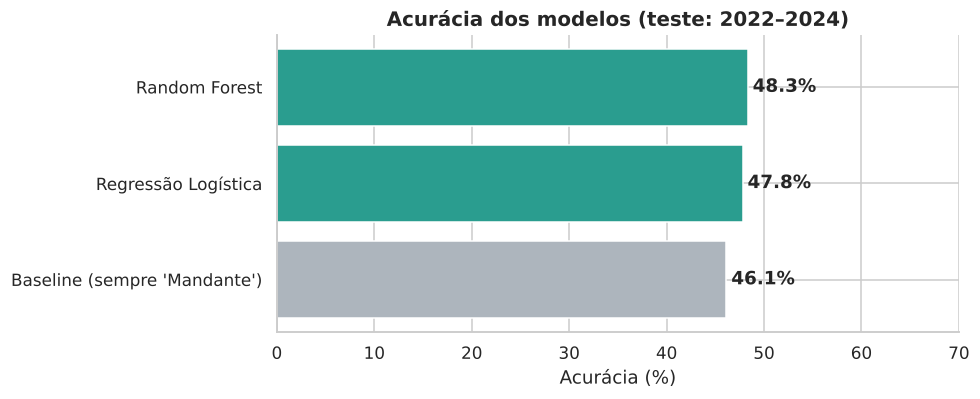

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.5))
cores_m = ["#adb5bd" if "Baseline" in n else "#2a9d8f" for n in res_df.index]
ax.barh(res_df.index, res_df.values * 100, color=cores_m)
for y, v in enumerate(res_df.values * 100):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center", fontweight="bold")
ax.set(title="Acurácia dos modelos (teste: 2022–2024)", xlabel="Acurácia (%)", xlim=(0, 70))
sns.despine()
salvar(fig, "09_modelos_acuracia")
plt.show()

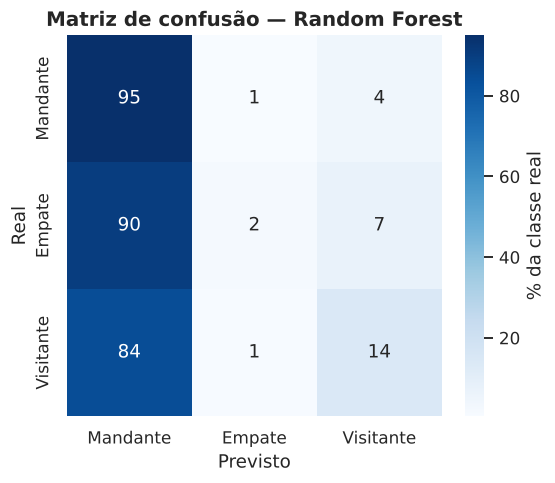

In [22]:
# Matriz de confusão do melhor modelo
melhor_nome = res_df.index[-1]
melhor = modelos[melhor_nome]
ordem = ["Mandante", "Empate", "Visitante"]
cm = confusion_matrix(y_te, melhor.predict(X_te), labels=ordem, normalize="true") * 100

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", xticklabels=ordem, yticklabels=ordem, ax=ax,
            cbar_kws={"label": "% da classe real"})
ax.set(title=f"Matriz de confusão — {melhor_nome}", xlabel="Previsto", ylabel="Real")
salvar(fig, "10_matriz_confusao")
plt.show()

### Interpretação

- Os modelos superam o baseline por uma margem **pequena** (cerca de 46% do baseline contra ~48% dos modelos). Isso é esperado: **futebol é um esporte de alta aleatoriedade** e um único gol muda o resultado.
- A matriz de confusão mostra o limite real do modelo: ele **prevê "Mandante" na grande maioria dos jogos** e praticamente nunca acerta empates ou vitórias do visitante. O ganho de acurácia vem de acertar um pouco mais os jogos em que o mandante é nitidamente superior.
- O objetivo aqui não é "vencer as casas de apostas", e sim mostrar um fluxo completo e **sem vazamento de dados**: engenharia de variáveis, divisão temporal, comparação com baseline e leitura crítica dos resultados.

## 7. Conclusões

| # | Pergunta | Resposta |
|---|----------|----------|
| 1 | Fator casa existe? | **Sim**: o mandante vence cerca de metade dos jogos, mas a taxa caiu de ~51% (2003–2016) para ~47% (2017–2024) |
| 2 | Gols por jogo | Cerca de **2,56 gols por jogo** (2,18 em 2018, o mínimo; 3,13 em 2005, o máximo); 1x0, 1x1 e 2x1 são os placares mais comuns |
| 3 | Maiores campeões (2006–2024) | **Palmeiras** lidera com 4 títulos; **São Paulo, Corinthians e Flamengo** têm 3 cada |
| 4 | Pontos necessários | Em média ~**77** para o título, ~**64** para o 4º lugar e ~**42** para escapar do rebaixamento |
| 5 | Casa vs. fora | Todos os 12 clubes analisados rendem mais em casa; a diferença vai de ~19 p.p. (Botafogo) a ~34 p.p. (Athletico-PR) |
| 6 | Dá para prever? | Só ligeiramente melhor que o baseline (~48% contra ~46%): **o acaso pesa muito no futebol** |

### Próximos passos
- Adicionar dados de **público, cartões e escanteios** para enriquecer o modelo.
- Incluir a **Série B** e comparar com outros campeonatos.
- Publicar um **dashboard interativo com Streamlit**.
- Testar modelos de **previsão de gols** (Poisson) em vez de apenas o resultado.